# Census Income: Exploratory Data Analysis

Goal: understand the data **before** modeling: its quality, its distributions, what relates to income, and where fairness or modeling problems might hide.

**Contents**
1. Setup and loading
2. Overview
3. Data quality (whitespace, `?`, duplicates)
4. Cleaning for analysis
5. Target balance
6. Numeric features
7. Categorical features
8. Features vs. target
9. Correlations
10. Fairness-relevant slices
11. Summary and modeling implications
12. Decisions

## 1. Setup and loading

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

LABEL = "salary"
POSITIVE = ">50K"                      # the class we call "positive"
RARE_THRESHOLD = 0.01                  # category share below this counts as "rare"
MIN_SLICE_N = 30                       # ignore tiny groups in rate charts

In [2]:
path = "data/census.csv"

raw = pd.read_csv(path, skipinitialspace=True)

## 2. Overview

In [3]:
print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns | memory {raw.memory_usage(deep=True).sum() / 1e6:.1f} MB")
raw.sample(5)

32,561 rows x 15 columns | memory 18.5 MB


,age,workclass,fnlgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,salary
24658,22,Private,175883,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Female,0,0,40,United-States,<=50K
20632,33,Private,137310,HS-grad,9,Never-married,Machine-op-inspct,Own-child,White,Female,0,0,40,?,<=50K
27366,32,Private,176992,10th,6,Never-married,Craft-repair,Unmarried,White,Male,0,0,40,United-States,<=50K
16434,33,Private,147700,HS-grad,9,Married-civ-spouse,Craft-repair,Husband,Other,Male,0,0,40,United-States,<=50K
5587,31,Private,34572,Assoc-voc,11,Married-civ-spouse,Handlers-cleaners,Husband,White,Male,0,0,45,United-States,<=50K


In [4]:
pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "n_unique": raw.nunique(),
    "example": raw.iloc[0],
})

,dtype,n_unique,example
age,int64,73,39
workclass,object,9,State-gov
fnlgt,int64,21648,77516
education,object,16,Bachelors
education-num,int64,16,13
marital-status,object,7,Never-married
occupation,object,15,Adm-clerical
relationship,object,6,Not-in-family
race,object,5,White
sex,object,2,Male


## 3. Data quality

Checks on the **raw** file: stray whitespace, `?` placeholders (not seen by `isna()`), duplicates, and label formatting.

In [5]:
def is_question(col):
    return col.astype(str).str.strip().eq("?")

quality = pd.DataFrame({
    "n_nan": raw.isna().sum(),
    "n_question_mark": raw.apply(is_question).sum(),
})
quality["pct_missing"] = ((quality.n_nan + quality.n_question_mark) / len(raw) * 100).round(2)

text_cols_raw = [c for c in raw.columns if raw[c].dtype == object or str(raw[c].dtype).startswith("str")]
quality["has_stray_spaces"] = [
    bool(c in text_cols_raw and (raw[c].dropna().astype(str) != raw[c].dropna().astype(str).str.strip()).any())
    for c in quality.index
]
print("duplicate rows:", raw.duplicated().sum(), f"({raw.duplicated().mean():.2%})")
print("column names with stray spaces:", [c for c in raw.columns if c != c.strip()] or "none")
print("label values:", raw[LABEL].astype(str).unique().tolist())
quality[(quality.n_nan > 0) | (quality.n_question_mark > 0) | quality.has_stray_spaces]

duplicate rows: 24 (0.07%)
column names with stray spaces: none
label values: ['<=50K', '>50K']


,n_nan,n_question_mark,pct_missing,has_stray_spaces
workclass,0,1836,5.64,False
occupation,0,1843,5.66,False
native-country,0,583,1.79,False


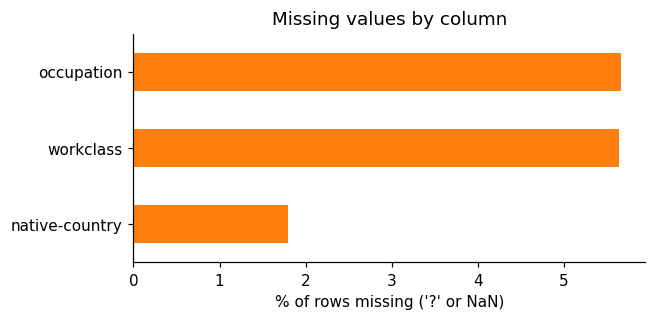

In [6]:
miss = quality["pct_missing"][quality["pct_missing"] > 0].sort_values()
if len(miss):
    ax = miss.plot.barh(figsize=(6, 0.4 * len(miss) + 1.5), color="tab:orange")
    ax.set_xlabel("% of rows missing ('?' or NaN)"); ax.set_title("Missing values by column"); plt.show()
else:
    print("No missing values found.")

## 4. Cleaning for analysis

For EDA we **keep** rows with missing values and label them `"Unknown"`. That way we can ask *do people with missing occupation earn differently?* Duplicates are removed and the label is normalized.
(The training pipeline may instead drop those rows. That choice is a modeling decision.)

In [7]:
def clean_for_eda(df):
    df = df.copy()
    df.columns = df.columns.str.strip()
    for c in df.columns:
        if df[c].dtype == object or str(df[c].dtype).startswith("str"):
            df[c] = df[c].str.strip()
    df = df.replace(["?", ""], np.nan)
    df = df.dropna(subset=[LABEL])
    df[LABEL] = df[LABEL].astype(str).str.strip().str.rstrip(".")
    num = df.select_dtypes("number").columns
    text = [c for c in df.columns if c not in num]
    df[text] = df[text].fillna("Unknown")
    return df.dropna().drop_duplicates().reset_index(drop=True)

data = clean_for_eda(raw)
assert POSITIVE in set(data[LABEL]), f"{POSITIVE!r} not in label values {data[LABEL].unique()}"
data["target"] = (data[LABEL] == POSITIVE).astype(int)

num_cols = [c for c in data.select_dtypes("number").columns if c != "target"]
cat_cols = [c for c in data.columns if c not in num_cols and c not in (LABEL, "target")]
BASE_RATE = data["target"].mean()

print(f"rows: {len(raw):,} -> {len(data):,}  (removed {len(raw) - len(data):,} duplicates/invalid)")
print("numeric    :", num_cols)
print("categorical:", cat_cols)

rows: 32,561 -> 32,537  (removed 24 duplicates/invalid)
numeric    : ['age', 'fnlgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
categorical: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']


## 5. Target balance

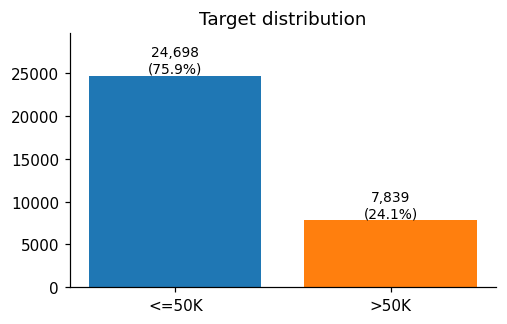

Positive-class (>50K) rate: 24.1%  |  majority-class baseline accuracy: 75.9%


In [8]:
counts = data[LABEL].value_counts()
fig, ax = plt.subplots(figsize=(5, 3))
bars = ax.bar(counts.index, counts.values, color=["tab:blue", "tab:orange"][: len(counts)])
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,}\n({v / len(data):.1%})", ha="center", va="bottom", fontsize=9)
ax.set_ylim(0, counts.max() * 1.2); ax.set_title("Target distribution"); plt.show()
print(f"Positive-class ({POSITIVE}) rate: {BASE_RATE:.1%}  |  majority-class baseline accuracy: {1 - BASE_RATE if BASE_RATE < .5 else BASE_RATE:.1%}")

## 6. Numeric features

In [9]:
desc = data[num_cols].describe().T
desc["skew"] = data[num_cols].skew()
desc["pct_zero"] = (data[num_cols] == 0).mean() * 100
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,skew,pct_zero
age,32537.0,38.59,13.64,17.0,28.0,37.0,48.0,90.0,0.56,0.00
fnlgt,32537.0,189780.85,105556.47,12285.0,117827.0,178356.0,236993.0,1484705.0,1.45,0.00
education-num,32537.0,10.08,2.57,1.0,9.0,10.0,12.0,16.0,-0.31,0.00
capital-gain,32537.0,1078.44,7387.96,0.0,0.0,0.0,0.0,99999.0,11.95,91.66
capital-loss,32537.0,87.37,403.10,0.0,0.0,0.0,0.0,4356.0,4.59,95.33
hours-per-week,32537.0,40.44,12.35,1.0,40.0,40.0,45.0,99.0,0.23,0.00


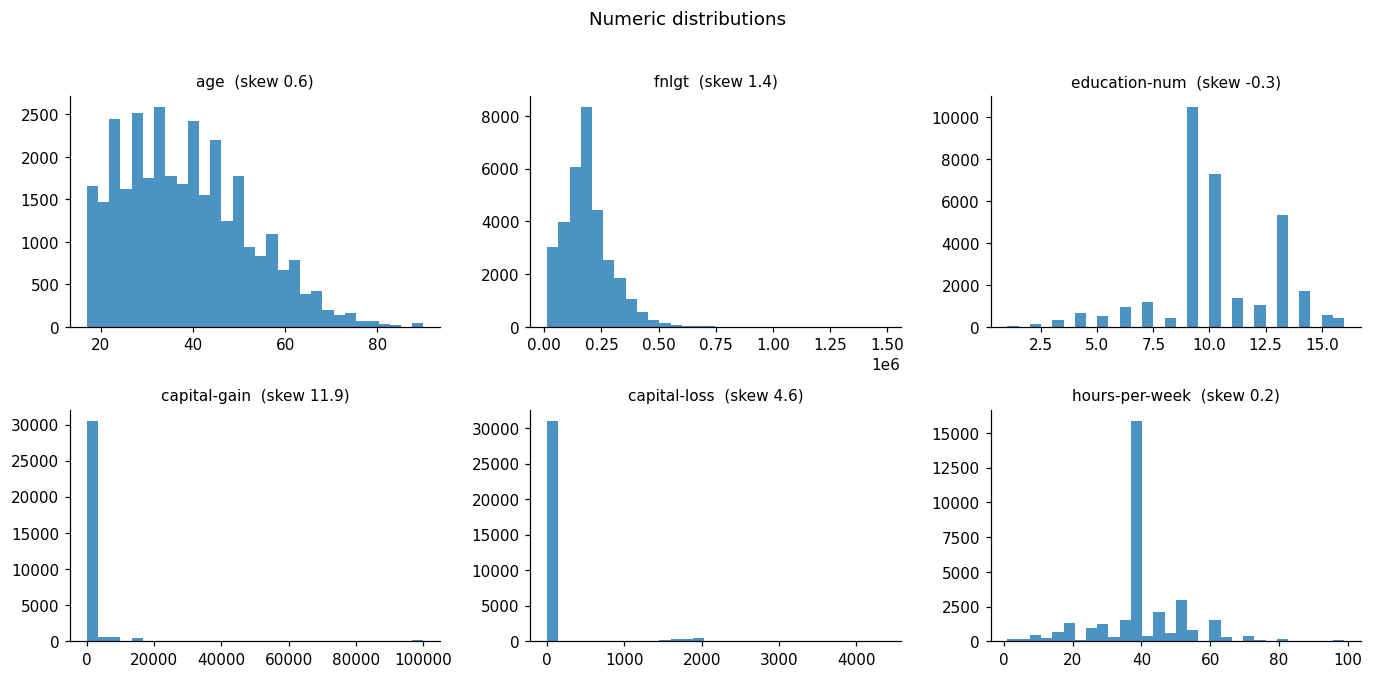

In [10]:
def grid(n, ncols=3, h=3.0, w=4.2):
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(w * ncols, h * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes[n:]:
        ax.axis("off")
    return fig, axes

fig, axes = grid(len(num_cols))
for ax, c in zip(axes, num_cols):
    ax.hist(data[c], bins=30, color="tab:blue", alpha=.8)
    ax.set_title(f"{c}  (skew {data[c].skew():.1f})", fontsize=10)
fig.suptitle("Numeric distributions", y=1.02); fig.tight_layout(); plt.show()

In [11]:
# Outliers by the 1.5 x IQR rule, and columns that are mostly zero
rows = []
for c in num_cols:
    q1, q3 = data[c].quantile([.25, .75]); iqr = q3 - q1
    out = ((data[c] < q1 - 1.5 * iqr) | (data[c] > q3 + 1.5 * iqr)).mean() * 100
    rows.append((c, round(out, 1), round((data[c] == 0).mean() * 100, 1), data[c].min(), data[c].max()))
pd.DataFrame(rows, columns=["column", "%outliers_IQR", "%zeros", "min", "max"]).set_index("column")

,%outliers_IQR,%zeros,min,max
column,,,,
age,0.4,0.0,17,90
fnlgt,3.1,0.0,12285,1484705
education-num,3.7,0.0,1,16
capital-gain,8.3,91.7,0,99999
capital-loss,4.7,95.3,0,4356
hours-per-week,27.7,0.0,1,99


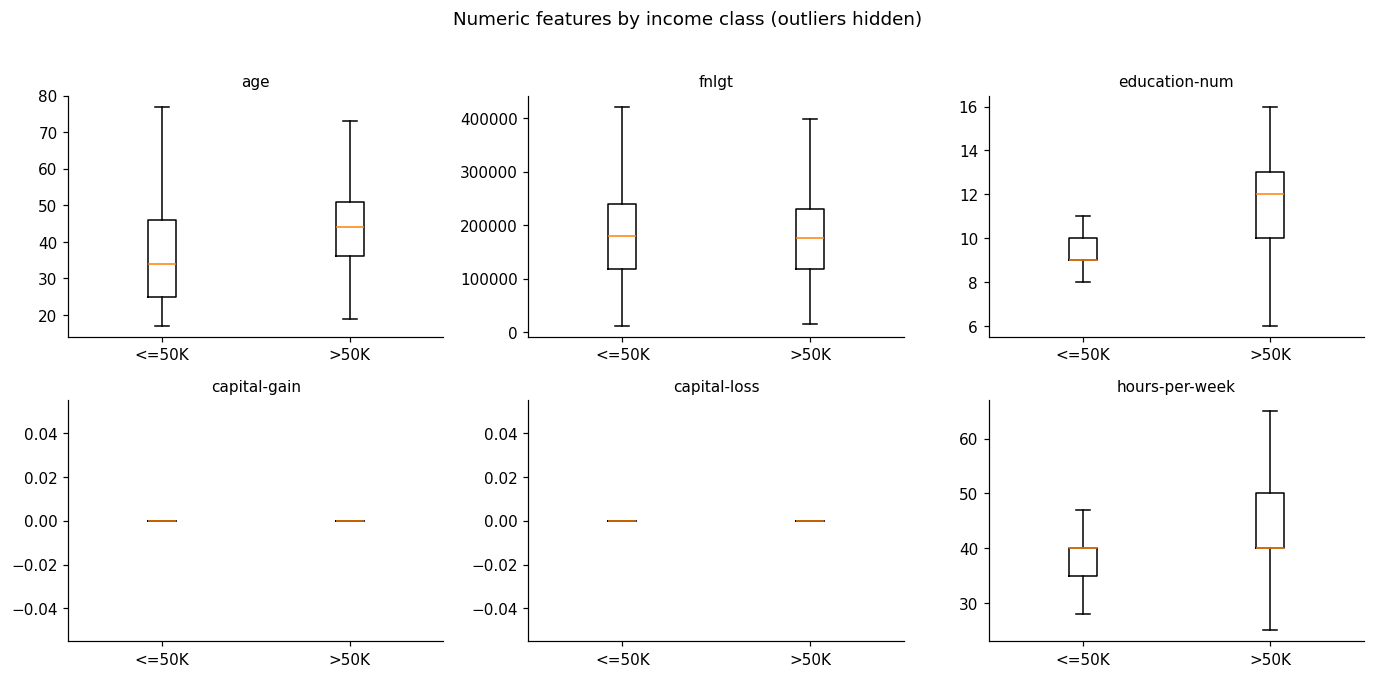

In [12]:
# Distribution by target class
fig, axes = grid(len(num_cols))
for ax, c in zip(axes, num_cols):
    groups = [data.loc[data[LABEL] == k, c] for k in sorted(data[LABEL].unique())]
    ax.boxplot(groups, tick_labels=sorted(data[LABEL].unique()), showfliers=False)
    ax.set_title(c, fontsize=10)
fig.suptitle("Numeric features by income class (outliers hidden)", y=1.02); fig.tight_layout(); plt.show()

## 7. Categorical features

In [13]:
card = []
for c in cat_cols:
    vc = data[c].value_counts(normalize=True)
    card.append((c, data[c].nunique(), vc.index[0], round(vc.iloc[0] * 100, 1), int((vc < RARE_THRESHOLD).sum())))
card = pd.DataFrame(card, columns=["column", "n_unique", "top_value", "top_share_%", f"n_rare(<{RARE_THRESHOLD:.0%})"]).set_index("column")
card

,n_unique,top_value,top_share_%,n_rare(<1%)
column,,,,
workclass,9,Private,69.7,2
education,16,HS-grad,32.3,2
marital-status,7,Married-civ-spouse,46.0,1
occupation,15,Prof-specialty,12.7,2
relationship,6,Husband,40.5,0
race,5,White,85.4,2
sex,2,Male,66.9,0
native-country,42,United-States,89.6,39


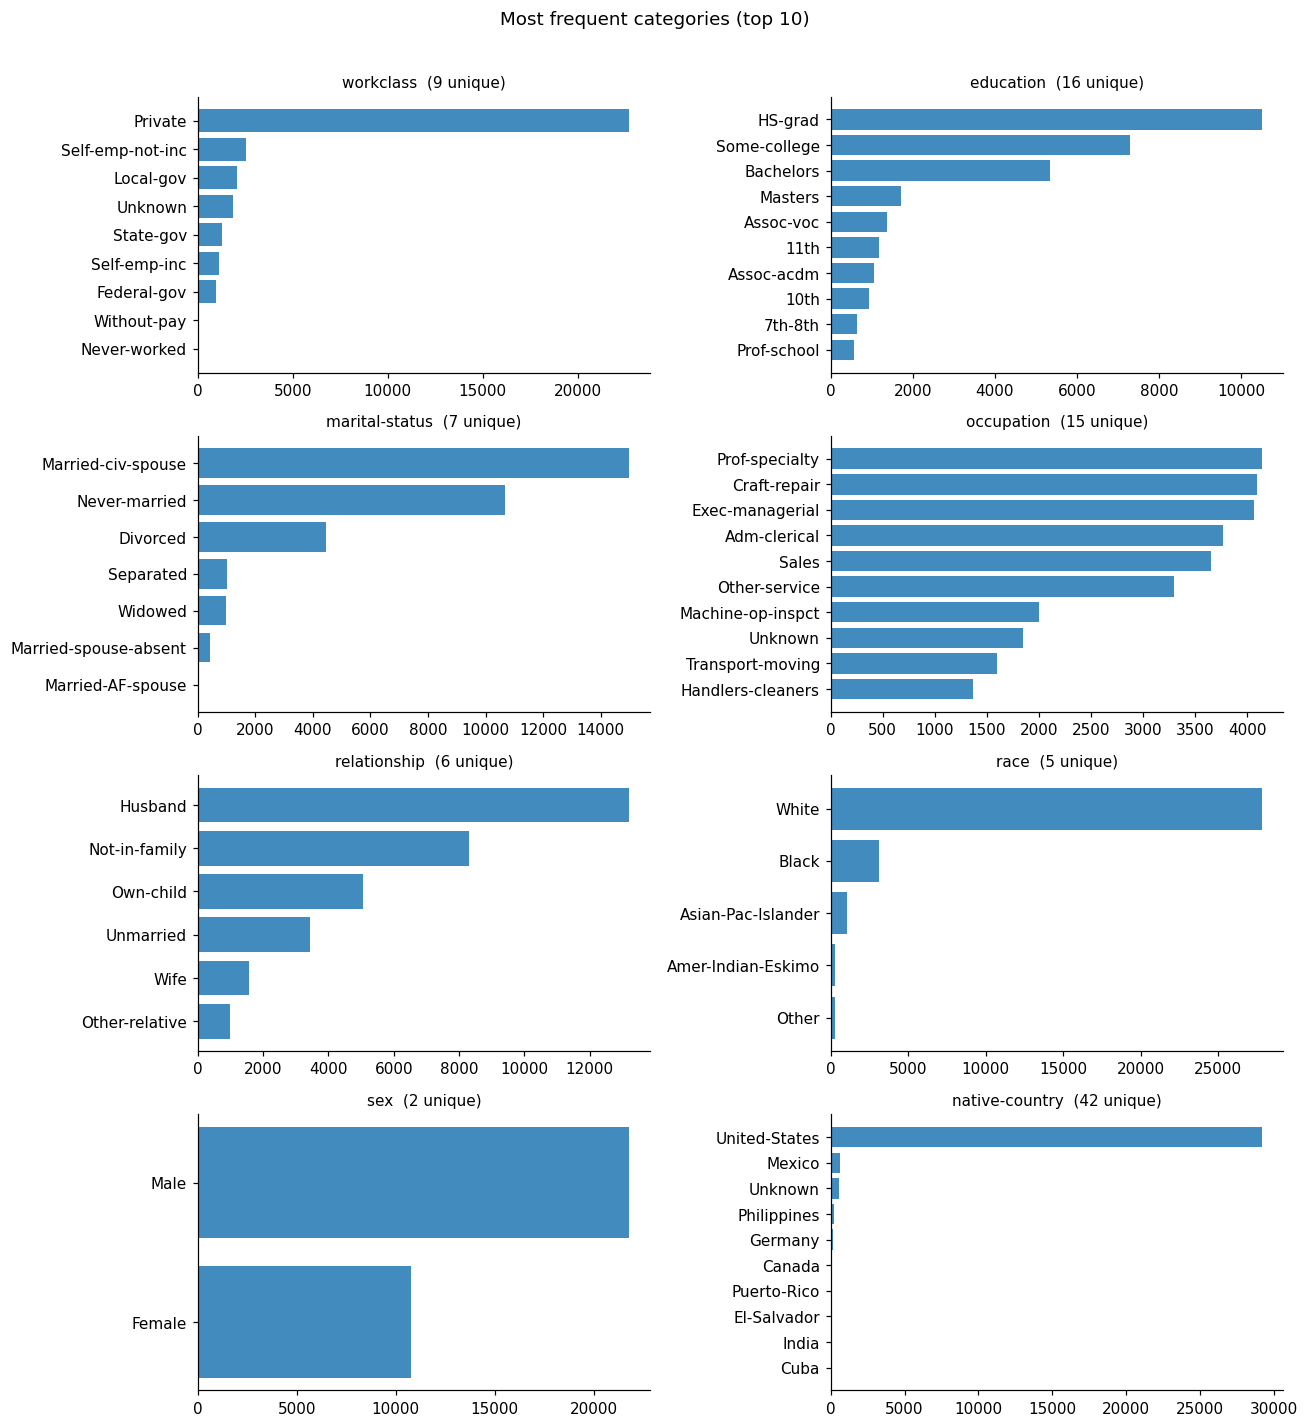

In [14]:
fig, axes = grid(len(cat_cols), ncols=2, h=3.2, w=6)
for ax, c in zip(axes, cat_cols):
    vc = data[c].value_counts().head(10)[::-1]
    ax.barh(vc.index.astype(str), vc.values, color="tab:blue", alpha=.85)
    ax.set_title(f"{c}  ({data[c].nunique()} unique)", fontsize=10)
fig.suptitle("Most frequent categories (top 10)", y=1.01); fig.tight_layout(); plt.show()

## 8. Features vs. target

### 8.1 Categorical: share earning `>50K` per category

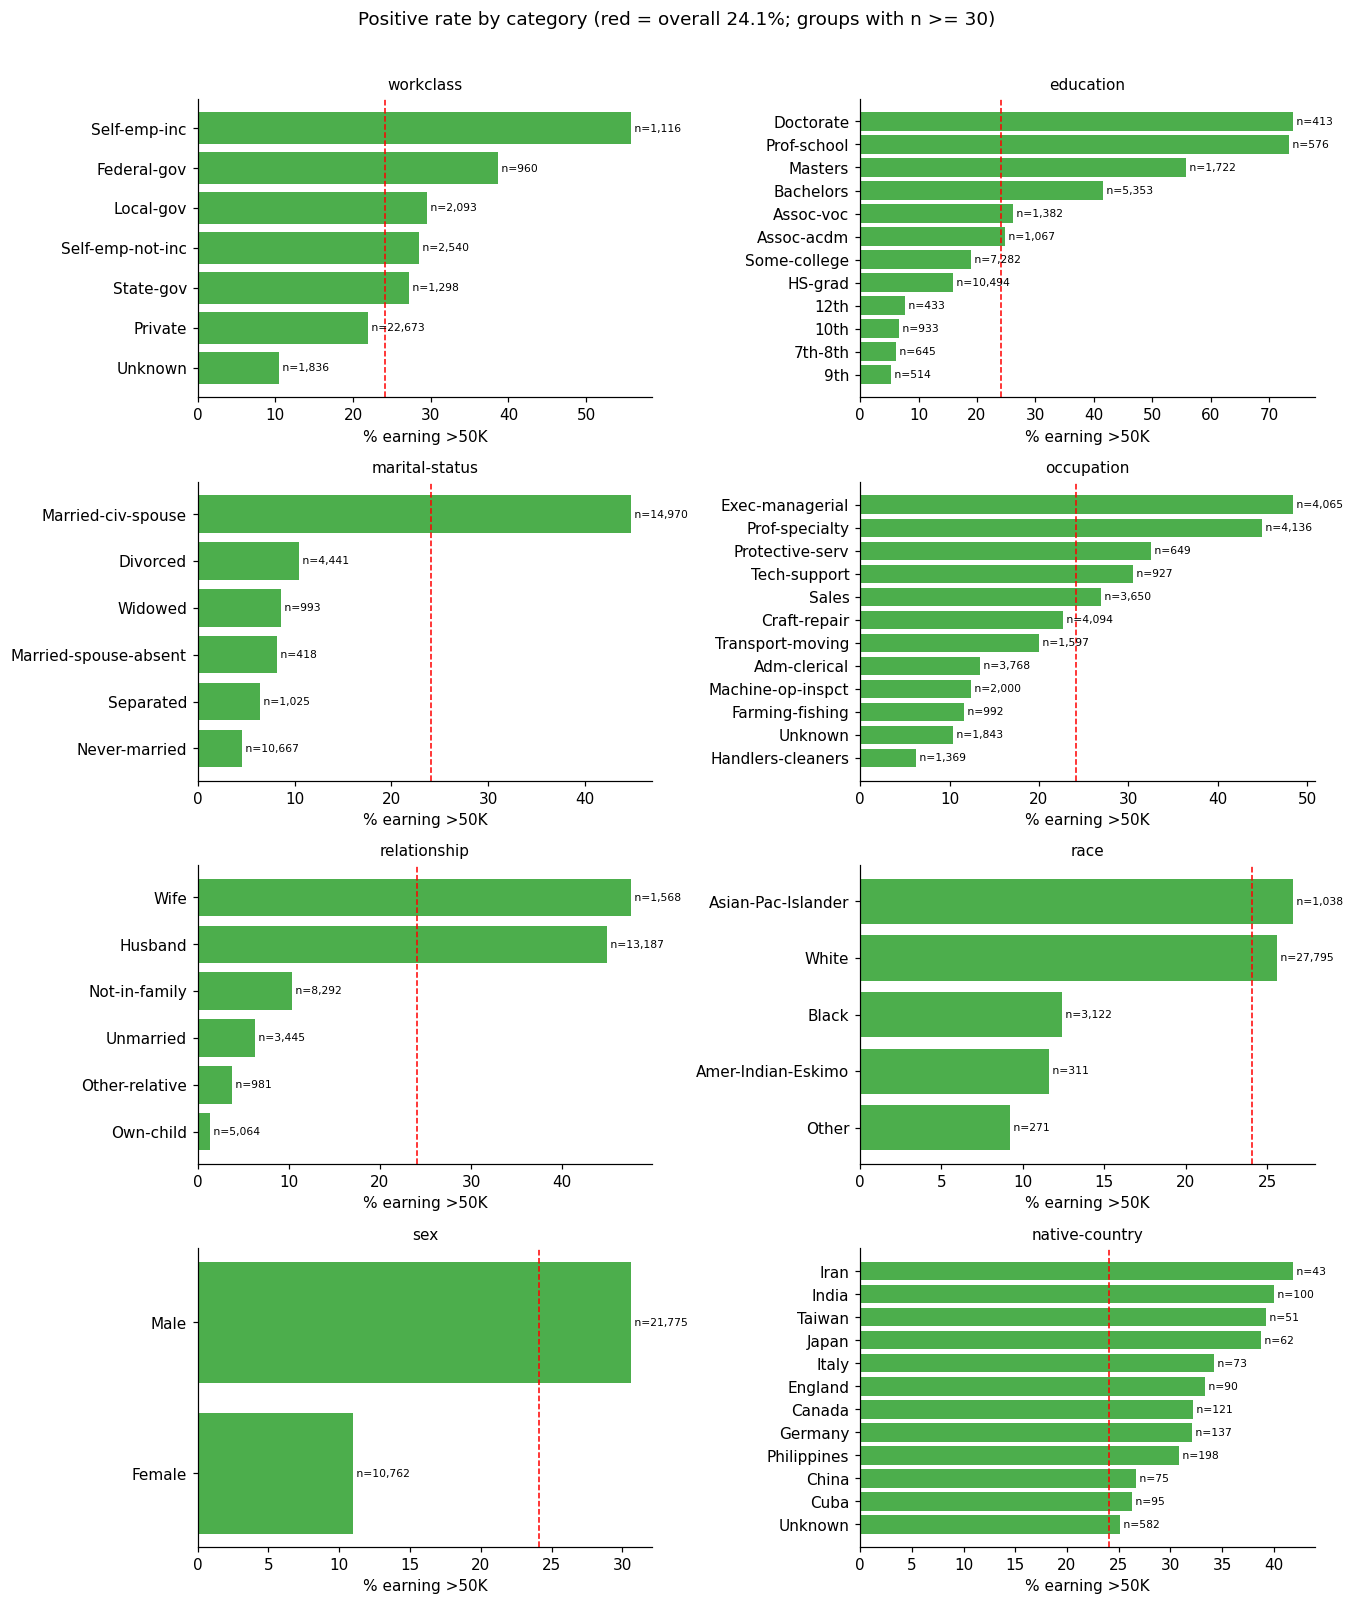

In [15]:
fig, axes = grid(len(cat_cols), ncols=2, h=3.6, w=6.2)
for ax, c in zip(axes, cat_cols):
    g = data.groupby(c)["target"].agg(["mean", "size"])
    g = g[g["size"] >= MIN_SLICE_N].sort_values("mean").tail(12)
    ax.barh(g.index.astype(str), g["mean"] * 100, color="tab:green", alpha=.85)
    ax.axvline(BASE_RATE * 100, color="red", ls="--", lw=1)
    for y, (m, s) in enumerate(zip(g["mean"], g["size"])):
        ax.text(m * 100, y, f" n={s:,}", va="center", fontsize=7)
    ax.set_title(c, fontsize=10); ax.set_xlabel("% earning >50K")
fig.suptitle(f"Positive rate by category (red = overall {BASE_RATE:.1%}; groups with n >= {MIN_SLICE_N})", y=1.01)
fig.tight_layout(); plt.show()

### 8.2 Numeric: positive rate across value bins

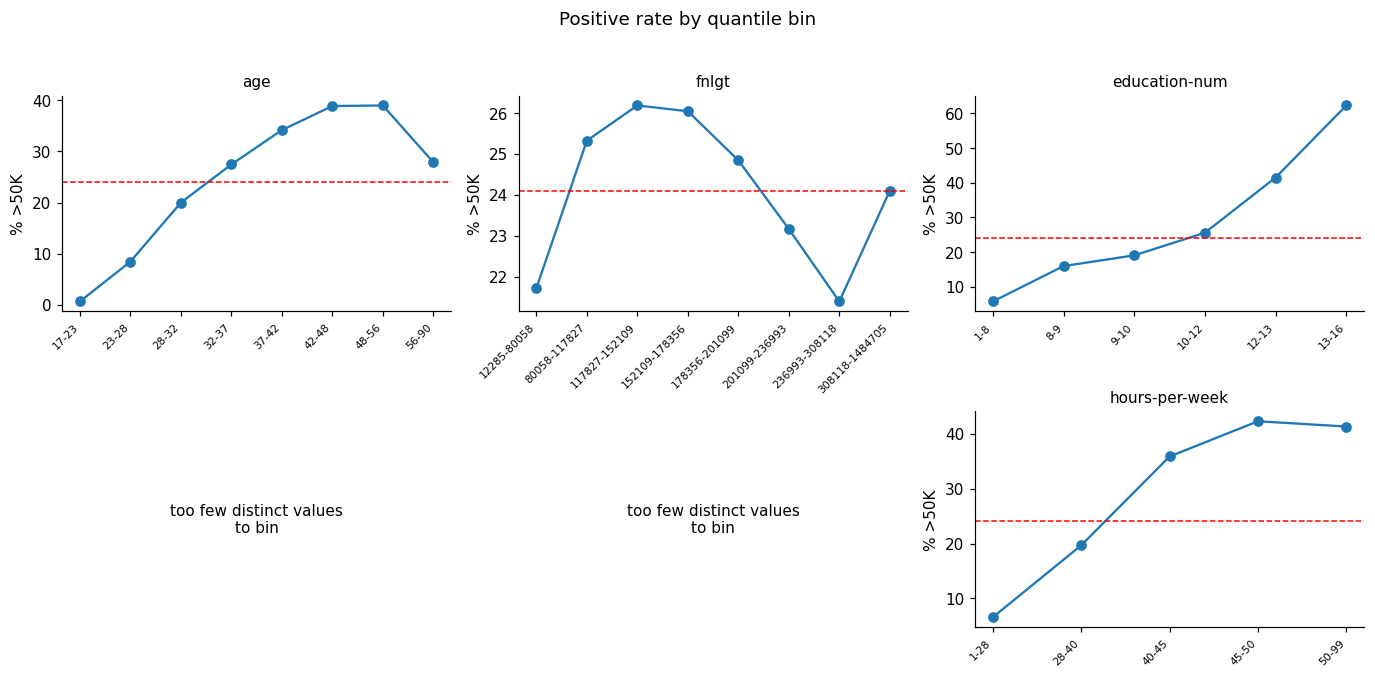

In [16]:
fig, axes = grid(len(num_cols))
for ax, c in zip(axes, num_cols):
    try:
        bins = pd.qcut(data[c], q=8, duplicates="drop")
    except ValueError:
        bins = None
    if bins is None or bins.nunique() < 2:
        ax.text(.5, .5, "too few distinct values\nto bin", ha="center", va="center"); ax.axis("off"); continue
    g = data.groupby(bins, observed=True)["target"].mean() * 100
    ax.plot(range(len(g)), g.values, marker="o")
    ax.set_xticks(range(len(g))); ax.set_xticklabels([f"{i.left:.0f}-{i.right:.0f}" for i in g.index], rotation=45, ha="right", fontsize=7)
    ax.axhline(BASE_RATE * 100, color="red", ls="--", lw=1); ax.set_title(c, fontsize=10); ax.set_ylabel("% >50K")
fig.suptitle("Positive rate by quantile bin", y=1.02); fig.tight_layout(); plt.show()

In [17]:
data.groupby(LABEL)[num_cols].agg(["mean", "median"]).T.round(1)

salary                    <=50K      >50K
age            mean        36.8      44.3
               median      34.0      44.0
fnlgt          mean    190345.9  188000.5
               median  179465.0  176063.0
education-num  mean         9.6      11.6
               median       9.0      12.0
capital-gain   mean       148.9    4007.2
               median       0.0       0.0
capital-loss   mean        53.2     195.1
               median       0.0       0.0
hours-per-week mean        38.8      45.5
               median      40.0      40.0

## 9. Correlations

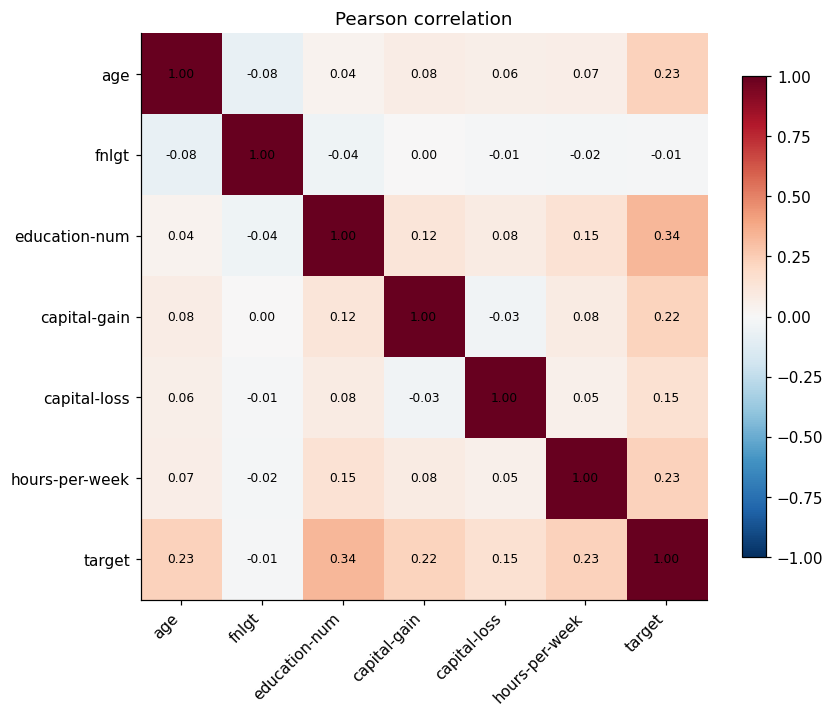

,corr_with_target
education-num,0.335
age,0.234
hours-per-week,0.230
capital-gain,0.223
capital-loss,0.151
fnlgt,-0.010


In [18]:
corr = data[num_cols + ["target"]].corr()
fig, ax = plt.subplots(figsize=(0.9 * len(corr) + 2, 0.8 * len(corr) + 1.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, shrink=.8); ax.set_title("Pearson correlation"); plt.show()
corr["target"].drop("target").sort_values(key=abs, ascending=False).round(3).to_frame("corr_with_target")

## 10. Fairness-relevant slices

The dataset contains protected attributes. Before modeling, see how outcomes and **sample sizes** differ by group. Small groups produce noisy metrics, and base-rate gaps may be reflected in the model's predictions.

In [19]:
prot = [c for c in ["sex", "race"] if c in data.columns]
for c in prot:
    g = data.groupby(c)["target"].agg(n="size", pct_positive=lambda s: round(s.mean() * 100, 1))
    g["share_of_data_%"] = (g["n"] / len(data) * 100).round(1)
    print(c); print(g.sort_values("n", ascending=False).to_string(), "\n")

sex
            n  pct_positive  share_of_data_%
sex                                         
Male    21775          30.6             66.9
Female  10762          11.0             33.1 

race
                        n  pct_positive  share_of_data_%
race                                                    
White               27795          25.6             85.4
Black                3122          12.4              9.6
Asian-Pac-Islander   1038          26.6              3.2
Amer-Indian-Eskimo    311          11.6              1.0
Other                 271           9.2              0.8 



In [20]:
if len(prot) == 2:
    a, b = prot
    rate = data.pivot_table(index=a, columns=b, values="target", aggfunc="mean") * 100
    size = data.pivot_table(index=a, columns=b, values="target", aggfunc="size")
    print(f"% earning >50K by {a} x {b}  (cells with n < {MIN_SLICE_N} masked)")
    print(rate.where(size >= MIN_SLICE_N).round(1).to_string())
    print(f"\ngroup sizes:")
    print(size.to_string())

% earning >50K by sex x race  (cells with n < 30 masked)
race    Amer-Indian-Eskimo  Asian-Pac-Islander  Black  Other  White
sex                                                                
Female                10.1                12.4    5.8    5.5   11.9
Male                  12.5                33.7   19.0   11.7   31.8

group sizes:
race    Amer-Indian-Eskimo  Asian-Pac-Islander  Black  Other  White
sex                                                                
Female                 119                 346   1555    109   8633
Male                   192                 692   1567    162  19162


## 11. Summary and modeling implications

In [21]:
top_num = corr["target"].drop("target").abs().sort_values(ascending=False).head(3)
top_cat = V[LABEL].drop(LABEL).sort_values(ascending=False).head(3)
skewed = data[num_cols].skew().abs().sort_values(ascending=False).head(3)
rare_total = int(card.filter(like="n_rare").sum().iloc[0])

lines = [
    f"Rows: {len(raw):,} raw -> {len(data):,} after removing duplicates",
    f"Positive-class rate: {BASE_RATE:.1%} (majority baseline accuracy {max(BASE_RATE, 1 - BASE_RATE):.1%})",
    f"Columns with missing values: {', '.join(miss.index[::-1]) if len(miss) else 'none'}",
    f"Most target-related numeric: {', '.join(f'{k} ({v:.2f})' for k, v in top_num.items())}",
    f"Most skewed numeric: {', '.join(f'{k} ({data[k].skew():.1f})' for k in skewed.index)}",
]
print("\n".join("- " + l for l in lines))

NameError: name 'V' is not defined

## 12. Decisions

- Missing values are dropped for training data
- Skewed numerics left untouched: shouldn't matter